# T5: преобразование текста в текст и дообучение для реферирования

Для обучения рекомендуется среда с графическим ускорителем. В блоке переменных можно уменьшить выборку и число шагов. Без ускорителя разумно выполнять только первые разделы и заранее подготовленный результат обучения.

In [ ]:
# %pip -q install "transformers>=4.45,<5" "datasets>=3,<5" "evaluate>=0.4,<1" "accelerate>=1,<2" "rouge_score>=0.1.2" "sentencepiece>=0.2" "pandas>=2"

In [ ]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM, DataCollatorForSeq2Seq,
    Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed,
)
import evaluate

# ===== ПЕРЕМЕННЫЕ ЭКСПЕРИМЕНТА =====
SEED = 42
DEMO_MODEL = "google/flan-t5-small"
TRAIN_MODEL = "google-t5/t5-small"  # классическая T5: текстовый префикс summarize:
DATASET = "duccd/billsum"
TRAIN_SIZE = 160
VALID_SIZE = 32
TEST_SIZE = 32
MAX_SOURCE_LENGTH = 384
MAX_TARGET_LENGTH = 96
TRAIN_STEPS = 60
BATCH_SIZE = 4
LEARNING_RATE = 5e-4
OUTPUT_DIR = Path("./outputs_t5_billsum")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
set_seed(SEED)
print("Устройство:", DEVICE)
print("PyTorch:", torch.__version__)

/home/dasha/work/NLP_ODS_autumn_2026/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Устройство: cuda
PyTorch: 2.15.0+cu132


## 1. Что представляет собой T5?
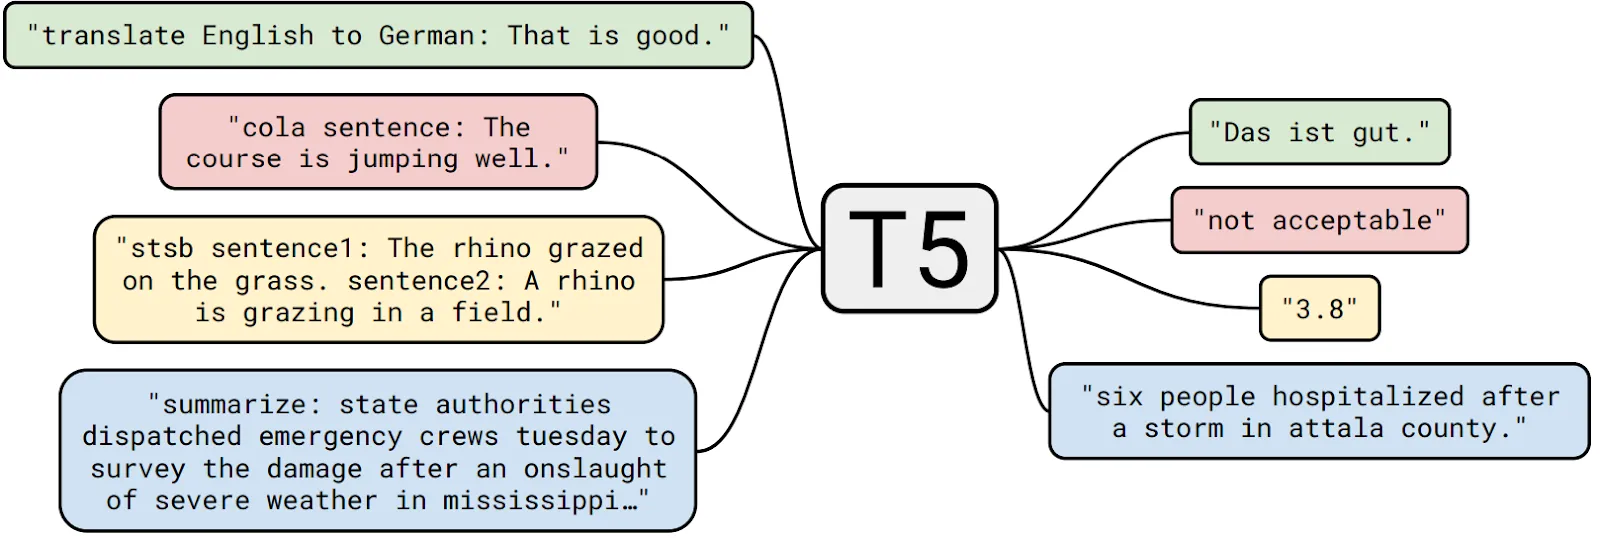

T5 — преобразователь с **кодировщиком и декодировщиком**. Кодировщик строит контекстные представления входной последовательности; декодировщик последовательно предсказывает токены ответа, используя самовнимание и внимание к выходу кодировщика.

Идея **text-to-text**: практически все задачи приводятся к предсказанию текстовой последовательности. В классической T5 тип задачи обычно задаётся префиксом (`summarize:`, `translate English to German:`). FLAN-T5 дополнительно прошла обучение на инструкциях, поэтому удобна для работы без специального дообучения.

При предобучении T5 использовалось восстановление удалённых фрагментов текста, а не обычное предсказание очередного токена всей исходной последовательности.




Демонстрация не является строгой оценкой качества: инструкция, длина и язык влияют на вывод. FLAN-T5 Small в первую очередь подходит для небольших **англоязычных** примеров.

In [ ]:
demo_tok = AutoTokenizer.from_pretrained(DEMO_MODEL)
demo_model = AutoModelForSeq2SeqLM.from_pretrained(DEMO_MODEL).to(DEVICE)
demo_model.eval()

def flan_generate(instruction, max_new_tokens=64, num_beams=4):
    inputs = demo_tok(instruction, return_tensors="pt", truncation=True, max_length=384).to(DEVICE)
    with torch.inference_mode():
        output = demo_model.generate(**inputs, max_new_tokens=max_new_tokens,
                                     num_beams=num_beams, do_sample=False)
    return demo_tok.decode(output[0], skip_special_tokens=True)

tasks = {
 "Реферирование": "Summarize in one sentence: The city council approved a new park on Monday. The park will open next spring and will include a playground and walking paths.",
 "Перевод": "Translate English to German: The new library opens tomorrow.",
 "Классификация": "Classify the sentiment as positive or negative: The delivery was fast and the product works perfectly.",
 "Исправление": "Correct the grammar: She don't likes reading books.",
 "Извлечение": "Extract the date and amount: The company paid $400 on March 12, 2025.",
}
for title, task in tasks.items():
    print(f"{title}: {flan_generate(task)}")

Loading weights: 100%|██████████| 190/190 [00:00<00:00, 1630.54it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
/home/dasha/work/NLP_ODS_autumn_2026/.venv/lib/python3.11/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


Реферирование: The city council has approved a new playground and walking paths.
Перевод: Die neue Bibliothek findet tomorrow.
Классификация: positive
Исправление: She doesn't like reading books.
Извлечение: The company paid $400 on March 12, 2025.




Ниже используется англоязычный корпус законодательных текстов с эталонными краткими содержаниями. Это **абстрактивное реферирование**: целевой текст не обязан дословно копировать фрагменты документа.

Срезы разделены до обучения; часть исходных текстов может обрезаться по `MAX_SOURCE_LENGTH`. Не следует выдавать результат этого небольшого эксперимента за качество на полном корпусе.

In [ ]:
from datasets import load_dataset

# Загружаем калифорнийские законодательные документы
raw = load_dataset(
    "duccd/billsum",
    data_files="ca_test.jsonl",
    split="train",
)

# Перемешиваем и формируем выборки
raw = raw.shuffle(seed=SEED)

needed = TRAIN_SIZE + VALID_SIZE + TEST_SIZE
assert len(raw) >= needed

train_raw = raw.select(range(0, TRAIN_SIZE))

valid_raw = raw.select(
    range(TRAIN_SIZE, TRAIN_SIZE + VALID_SIZE)
)

test_raw = raw.select(
    range(
        TRAIN_SIZE + VALID_SIZE,
        needed,
    )
)

print("Train:", len(train_raw))
print("Valid:", len(valid_raw))
print("Test:", len(test_raw))
print(train_raw.column_names)

Train: 160
Valid: 32
Test: 32
['bill_id', 'text', 'summary', 'title', 'sum_len', 'text_len']




В целевых последовательностях `labels` содержатся идентификаторы токенов эталонного содержания. При формировании пакета токены заполнения заменяются на `-100`, чтобы функция потерь их игнорировала. `DataCollatorForSeq2Seq` также умеет выполнять динамическое дополнение до длины самой длинной последовательности в пакете.

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(TRAIN_MODEL)
model = AutoModelForSeq2SeqLM.from_pretrained(TRAIN_MODEL).to(DEVICE)
PREFIX = "summarize: "

def preprocess(batch):
    sources = [PREFIX + text for text in batch["text"]]
    encoded = tokenizer(sources, max_length=MAX_SOURCE_LENGTH, truncation=True)
    targets = tokenizer(text_target=batch["summary"], max_length=MAX_TARGET_LENGTH,
                        truncation=True)
    encoded["labels"] = targets["input_ids"]
    return encoded

train_ds = train_raw.map(preprocess, batched=True, remove_columns=train_raw.column_names)
valid_ds = valid_raw.map(preprocess, batched=True, remove_columns=valid_raw.column_names)
test_ds = test_raw.map(preprocess, batched=True, remove_columns=test_raw.column_names)
collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=model, label_pad_token_id=-100)
batch = collator([train_ds[0], train_ds[1]])
print({key: tuple(value.shape) for key, value in batch.items()})
print("Количество позиций -100:", int((batch["labels"] == -100).sum()))

Loading weights: 100%|██████████| 131/131 [00:00<00:00, 1668.16it/s]


{'input_ids': (2, 384), 'attention_mask': (2, 384), 'labels': (2, 96), 'decoder_input_ids': (2, 96)}
Количество позиций -100: 0


При обучении используется **принудительное предъявление эталонной последовательности** (*teacher forcing*): при предсказании следующего токена декодировщик получает предыдущие эталонные токены (сдвинутые на один шаг). Модель минимизирует среднюю отрицательную логарифмическую вероятность эталонных токенов, исключая `-100`. При генерации следующий токен зависит от уже **сгенерированных** токенов. Это приводит к различию распределений входов декодировщика на обучении и применении.

In [ ]:
# Посмотрим на маскирование и декодирование цели.
item = batch["labels"][0].tolist()
readable = [tid if tid != -100 else tokenizer.pad_token_id for tid in item]
print(tokenizer.decode(readable, skip_special_tokens=True)[:450])
print("Токены декодировщика:", tokenizer.convert_ids_to_tokens(readable[:20]))

The California Global Warming Solutions Act of 2006 designates the State Air Resources Board as the state agency charged with monitoring and regulating sources of emissions of greenhouse gases. The state board is required to approve a statewide greenhouse gas emissions limit equivalent to the statewide greenhouse gas emissions level in 1990 to be achieved by 2020. The state board is also required to complete a comprehensive strategy to reduce emi
Токены декодировщика: ['▁The', '▁California', '▁Global', '▁Warm', 'ing', '▁Solutions', '▁Act', '▁of', '▁2006', '▁design', 'ates', '▁the', '▁State', '▁Air', '▁Resources', '▁Board', '▁as', '▁the', '▁state', '▁agency']


In [ ]:
def summarize_one(current_model, text, beams=4, min_tokens=12, max_tokens=96):
    inputs = tokenizer(PREFIX + text, truncation=True, max_length=MAX_SOURCE_LENGTH,
                       return_tensors="pt").to(next(current_model.parameters()).device)
    current_model.eval()
    with torch.inference_mode():
        ids = current_model.generate(**inputs, num_beams=beams, do_sample=False,
                                     min_new_tokens=min_tokens, max_new_tokens=max_tokens)
    return tokenizer.decode(ids[0], skip_special_tokens=True)

preview_idx = list(range(min(3, len(test_raw))))
baseline_predictions = [summarize_one(model, test_raw[i]["text"]) for i in preview_idx]
for i, pred in zip(preview_idx, baseline_predictions):
    print(f"\nПРИМЕР {i}\nДО: {pred}\nЭТАЛОН: {test_raw[i]['summary'][:360]}")


ПРИМЕР 0
ДО: the Legislature finds and declares all of the following: a) in march 2014, a gas leak was detected beneath the community of Arvin, California. existing regulations for the regular testing and evaluation of smaller diameter pipelines were insufficient to protect that community from a serious gas leak. the division of oil, gas, and geothermal resources should review and reassess its existing regulations for active gas pipelines that are four inches or less
ЭТАЛОН: Existing law requires the Division of Oil, Gas, and Geothermal Resources to prescribe minimum facility maintenance standards for oil and gas production facilities, including pipelines that are not under the jurisdiction of the State Fire Marshal. Under the division’s regulations, an owner or operator of an active environmentally sensitive gas pipeline that i

ПРИМЕР 1
ДО: for each taxable year beginning on or after July 1, 2008, any credit allowed to a taxpayer under this chapter that is an eligible credit may be 


### Оценивание качества автоматического реферирования: ROUGE

Для оценки автоматически сформированных кратких содержаний часто используется семейство метрик **ROUGE** (*Recall-Oriented Understudy for Gisting Evaluation*). Эти метрики измеряют степень лексического совпадения между сгенерированным текстом и эталонным кратким содержанием.

В отличие от классификации, где мы можем непосредственно сравнить предсказанный класс с правильным, при реферировании существует множество допустимых вариантов ответа. Поэтому точное совпадение текстов не является подходящей мерой качества.

#### ROUGE-1 и ROUGE-2

**ROUGE-N** оценивает совпадение последовательностей из $N$ токенов (N-грамм) между сгенерированным и эталонным текстами.

- **ROUGE-1** — совпадение отдельных токенов (униграмм).
- **ROUGE-2** — совпадение пар соседних токенов (биграмм).

Для множества N-грамм определяются точность и полнота:

$$
P_N = \frac{M_N}{C_N},
\qquad
R_N = \frac{M_N}{G_N},
$$

где:

- $M_N$ — число совпавших N-грамм с учетом их кратности;
- $C_N$ — общее число N-грамм в сгенерированном тексте;
- $G_N$ — общее число N-грамм в эталонном тексте.

На практике часто используют **F1-меру**, объединяющую точность и полноту:

$$
F_{1,N} = \frac{2P_NR_N}{P_N+R_N}.
$$

Если точность и полнота одновременно равны нулю, полагаем $F_{1,N}=0$.

#### ROUGE-L

**ROUGE-L** основана на длине наибольшей общей подпоследовательности (*Longest Common Subsequence*, LCS) двух текстов.

Подпоследовательность сохраняет порядок токенов, но не требует, чтобы они располагались непосредственно друг за другом.

Пусть $L$ — длина наибольшей общей подпоследовательности, $m$ — число токенов в сгенерированном тексте, $n$ — в эталонном. Тогда:

$$
P_{LCS} = \frac{L}{m},
\qquad
R_{LCS} = \frac{L}{n},
$$

$$
F_{1,LCS} =
\frac{2P_{LCS}R_{LCS}}{P_{LCS}+R_{LCS}}.
$$

ROUGE-L позволяет учитывать не только совпадение отдельных слов, но и частичное сохранение их последовательности.

#### Почему используем ROUGE?

Для нашего эксперимента ROUGE удобна по нескольким причинам:

1. **Не требует дополнительной модели оценивания** — достаточно сгенерированного и эталонного текстов.
2. **Быстро вычисляется** и подходит для регулярного оценивания во время дообучения.
3. **Позволяет сравнивать контрольные точки модели** до и после дообучения при одинаковом тестовом наборе.
4. **Даёт несколько взаимодополняющих показателей**: совпадение слов (ROUGE-1), локальных последовательностей (ROUGE-2) и более длинных упорядоченных фрагментов (ROUGE-L).

В нашем ноутбуке библиотека `evaluate` с реализацией `rouge` по умолчанию возвращает F1-варианты этих метрик.

**Ограничения:** ROUGE оценивает преимущественно лексическое сходство, а не смысловую эквивалентность. Корректный пересказ другими словами может получить невысокую оценку. И наоборот, текст с высоким ROUGE может содержать фактические ошибки.

Поэтому при анализе результатов необходимо дополнительно просматривать сгенерированные краткие содержания и проверять сохранение ключевых фактов, чисел и именованных сущностей.


In [ ]:
rouge = evaluate.load("rouge")

def compute_metrics(eval_prediction):
    predictions, labels = eval_prediction
    if isinstance(predictions, tuple):
        predictions = predictions[0]
    labels = np.where(labels == -100, tokenizer.pad_token_id, labels)
    prediction_text = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    label_text = tokenizer.batch_decode(labels, skip_special_tokens=True)
    metrics = rouge.compute(predictions=prediction_text, references=label_text,
                            use_stemmer=True)
    metrics["gen_len"] = float(np.mean(np.sum(predictions != tokenizer.pad_token_id, axis=1)))
    return {k: round(float(v), 4) for k, v in metrics.items()}



Шагов обучения: 60


### Дообучение через Seq2SeqTrainer

`predict_with_generate=True` позволяет вычислять качество по **сгенерированным** последовательностям. В этом учебном эксперименте используется ограничение по числу шагов: модель может не успеть сойтись, поэтому низкие метрики не означают, что архитектура непригодна.

Ключевые параметры:
- `per_device_train_batch_size`: размер пакета на устройство;
- `gradient_accumulation_steps`: накопление градиентов;
- `learning_rate`: шаг оптимизации;
- `max_steps`: число обновлений параметров;
- `generation_max_length`: максимальная длина генерируемой последовательности при оценивании;
- `eval_strategy`: периодичность проверки.

In [ ]:
training_args = Seq2SeqTrainingArguments(
    output_dir=str(OUTPUT_DIR),
    max_steps=TRAIN_STEPS,
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    gradient_accumulation_steps=2,
    predict_with_generate=True,
    generation_max_length=MAX_TARGET_LENGTH,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="no",
    logging_steps=10,
    report_to="none",
    fp16=torch.cuda.is_available(),
    seed=SEED,
)
trainer = Seq2SeqTrainer(
    model=model, args=training_args, train_dataset=train_ds, eval_dataset=valid_ds,
    data_collator=collator, processing_class=tokenizer, compute_metrics=compute_metrics,
)
print("Шагов обучения:", TRAIN_STEPS)

In [ ]:
# Запуск обучения. На CPU может выполняться долго.
train_result = trainer.train()
print(train_result.metrics)
print("Проверочная выборка:", trainer.evaluate())

Step,Training Loss,Validation Loss,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
20,5.822815,2.458673,0.398400,0.163600,0.279200,0.278400,95.000000
40,5.172474,2.368728,0.436500,0.192800,0.304100,0.304500,95.000000
60,4.845437,2.355608,0.395700,0.155400,0.280900,0.280600,95.000000


{'train_runtime': 37.89, 'train_samples_per_second': 12.668, 'train_steps_per_second': 1.584, 'total_flos': 48723048529920.0, 'train_loss': 5.384580739339193, 'epoch': 3.0}


Training Loss,Validation Loss,Step,Rouge1,Rouge2,Rougel,Rougelsum,Gen Len
4.845437,2.355608,60,0.395700,0.155400,0.280900,0.280600,95.000000


Проверочная выборка: {'eval_loss': 2.3556079864501953, 'eval_rouge1': 0.3957, 'eval_rouge2': 0.1554, 'eval_rougeL': 0.2809, 'eval_rougeLsum': 0.2806, 'eval_gen_len': 95.0}


Для корректного численного сравнения на тестовой выборке надо **отдельно** вычислить качество исходной модели на всех тестовых объектах до обучения. Выше сохранены только три примера исходных ответов; не следует сравнивать частичную исходную оценку с полной итоговой. Ниже показан качественный разбор и количественная оценка **только** итоговой модели.

In [ ]:
after_predictions = [summarize_one(model, test_raw[i]["text"]) for i in preview_idx]
for i, before, after in zip(preview_idx, baseline_predictions, after_predictions):
    print(f"\nПРИМЕР {i}")
    print("ДО:", before)
    print("ПОСЛЕ:", after)
    print("ЭТАЛОН:", test_raw[i]["summary"][:600])
print("\nТестовая выборка (после обучения):", trainer.predict(test_ds).metrics)

[transformers] Both `max_new_tokens` (=96) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=12) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=96) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `min_new_tokens` (=12) and `min_length`(=0) seem to have been set. `min_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/t


ПРИМЕР 0
ДО: the Legislature finds and declares all of the following: a) in march 2014, a gas leak was detected beneath the community of Arvin, California. existing regulations for the regular testing and evaluation of smaller diameter pipelines were insufficient to protect that community from a serious gas leak. the division of oil, gas, and geothermal resources should review and reassess its existing regulations for active gas pipelines that are four inches or less
ПОСЛЕ: Existing law requires the Division of Oil, Gas, and Geothermal Resources to review and reassess its existing regulations for active gas pipelines that are four inches or less in diameter and update its regulations to ensure the integrity of those active gas pipelines and to prevent, as far as possible, damage to life, health, property, and natural resources. Existing law requires the Division of Oil, Gas, and Geothermal Resources to review and re
ЭТАЛОН: Existing law requires the Division of Oil, Gas, and Geotherma


Тестовая выборка (после обучения): {'test_loss': 2.4930930137634277, 'test_rouge1': 0.4277, 'test_rouge2': 0.1634, 'test_rougeL': 0.2909, 'test_rougeLsum': 0.2919, 'test_gen_len': 95.0, 'test_runtime': 9.6353, 'test_samples_per_second': 3.321, 'test_steps_per_second': 0.83}


Изменение декодирования не меняет параметры модели. `num_beams > 1` использует лучевой поиск; `do_sample=True` включает случайный выбор токенов. Температура имеет смысл именно при стохастической генерации.

In [ ]:
example = test_raw[0]["text"]
input_ids = tokenizer(PREFIX + example, return_tensors="pt", max_length=MAX_SOURCE_LENGTH,
                      truncation=True).to(DEVICE)
strategies = {
    "Жадная": dict(do_sample=False, num_beams=1),
    "Лучевой поиск": dict(do_sample=False, num_beams=4),
    "Случайная выборка": dict(do_sample=True, temperature=0.8, top_p=0.9, num_beams=1),
}
model.eval()
for name, params in strategies.items():
    with torch.inference_mode():
        output = model.generate(**input_ids, max_new_tokens=80, **params)
    print(name, ":", tokenizer.decode(output[0], skip_special_tokens=True), "\n")

[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Жадная : Existing law requires the Division of Oil, Gas, and Geothermal Resources to review and reassess existing regulations for active gas pipelines that are four inches or less in diameter and update its regulations to ensure the integrity of those active gas pipelines and to prevent, as far as possible, damage to life, health, property, and natural resources. Existing law requires the Division 



[transformers] Both `max_new_tokens` (=80) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Лучевой поиск : Existing law requires the Division of Oil, Gas, and Geothermal Resources to review and reassess existing regulations for active gas pipelines that are four inches or less in diameter and update its regulations to ensure the integrity of those active gas pipelines and to prevent, as far as possible, damage to life, health, property, and natural resources. Existing law requires the Division 

Случайная выборка : Existing law, the Division of Oil, Gas, and Geothermal Resources, establishes the Department of Oil, Gas, and Geothermal Resources, as defined, to review and reassess its existing regulations for active gas pipelines that are four inches or less in diameter and update its regulations to ensure the integrity of those active gas pipelines and to prevent, as far 



In [1]:

import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from transformers import T5Tokenizer

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer_ru = T5Tokenizer.from_pretrained(
    "cointegrated/rut5-base-multitask",
    backend="sentencepiece",
)
model_ru = AutoModelForSeq2SeqLM.from_pretrained("cointegrated/rut5-base-multitask").to(device)
model_ru.eval()


tokenizer_config.json:   0%|          | 0.00/260 [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  828kB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/65.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  977MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


T5ForConditionalGeneration(
  (shared): Embedding(30000, 768)
  (encoder): T5Stack(
    (embed_tokens): Embedding(30000, 768)
    (block): ModuleList(
      (0): T5Block(
        (layer): ModuleList(
          (0): T5LayerSelfAttention(
            (SelfAttention): T5Attention(
              (q): Linear(in_features=768, out_features=768, bias=False)
              (k): Linear(in_features=768, out_features=768, bias=False)
              (v): Linear(in_features=768, out_features=768, bias=False)
              (o): Linear(in_features=768, out_features=768, bias=False)
              (relative_attention_bias): Embedding(32, 12)
            )
            (layer_norm): T5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): T5LayerFF(
            (DenseReluDense): T5DenseGatedActDense(
              (wi_0): Linear(in_features=768, out_features=2048, bias=False)
              (wi_1): Linear(in_features=768, out_features=2048, bias=False)
              (wo):

In [3]:
def generate_ru(task, text, max_new_tokens=100):
    prompt = f"{task} | {text}"

    inputs = tokenizer_ru(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512,
    ).to(device)

    with torch.inference_mode():
        outputs = model_ru.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.2,
        )

    return tokenizer_ru.decode(
        outputs[0],
        skip_special_tokens=True,
    )

Примеры задач, на которых модель была дообучена

In [4]:
examples = [
    (
        "paraphrase",
        "Исследователи разработали новую модель, "
        "которая позволяет быстрее обрабатывать большие объёмы текста."
    ),
    (
        "simplify",
        "Применение современных методов машинного обучения "
        "способствует существенному повышению эффективности "
        "автоматизированной обработки текстовой информации."
    ),
    (
        "headline",
        "Компания представила новую систему машинного перевода. "
        "Разработчики утверждают, что она поддерживает более "
        "ста языков и обеспечивает высокое качество перевода."
    ),
    (
        "translate ru-en",
        "Учёные представили новую модель для автоматического "
        "реферирования научных статей."
    ),
    (
        "fill",
        "Современные языковые модели позволяют автоматически "
        "___ большие тексты и выделять основную информацию."
    ),
    (
        "ask",
        "Александр Пушкин родился в Москве в 1799 году."
    ),
]

for task, text in examples:
    print(f"\n{'=' * 70}")
    print(f"ЗАДАЧА: {task}")
    print(f"ВХОД: {text}")
    print(f"ОТВЕТ: {generate_ru(task, text)}")



ЗАДАЧА: paraphrase
ВХОД: Исследователи разработали новую модель, которая позволяет быстрее обрабатывать большие объёмы текста.
ОТВЕТ: Исследователи разработали новую модель, которая позволяет быстрее обрабатывать большие объёмы текста.

ЗАДАЧА: simplify
ВХОД: Применение современных методов машинного обучения способствует существенному повышению эффективности автоматизированной обработки текстовой информации.
ОТВЕТ: Применение современных методов машинного обучения способствует повышению эффективности автоматизированной обработки текстовой информации.

ЗАДАЧА: headline
ВХОД: Компания представила новую систему машинного перевода. Разработчики утверждают, что она поддерживает более ста языков и обеспечивает высокое качество перевода.
ОТВЕТ: Компания представила новую систему машинного перевода

ЗАДАЧА: translate ru-en
ВХОД: Учёные представили новую модель для автоматического реферирования научных статей.
ОТВЕТ: The scientists introduced a new model for automatic refering scientific artic


### Источники
- [Официальный пример дообучения T5 для реферирования](https://huggingface.co/docs/transformers/v4.57.1/en/tasks/summarization)
- [Исходная статья T5](https://arxiv.org/abs/1910.10683)
- [FLAN: обучение на инструкциях](https://arxiv.org/abs/2210.11416)
- [BillSum](https://huggingface.co/datasets/billsum)